## Day 1: Logistic Regression from Scratch

In [1]:
import numpy as np


In [2]:
X = np.array([
    [1, 1],
    [2, 2],
    [3, 3],
    [4, 4],
    [5, 5]
])

y = np.array([0, 0, 0, 1, 1])

print(X)
print(y)

[[1 1]
 [2 2]
 [3 3]
 [4 4]
 [5 5]]
[0 0 0 1 1]


In [3]:
%pip install numpy

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 24.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [4]:
import numpy as np

In [5]:
weights = np.zeros(2)
bias = 0

print("Weights:", weights)
print("Bias:", bias)

Weights: [0. 0.]
Bias: 0


In [6]:
def sigmoid(z):
    return 1 / (1 + np.exp(-z))

In [7]:
z = np.dot(X, weights) + bias
predictions = sigmoid(z)

print("Z:", z)
print("Predictions:", predictions)

Z: [0. 0. 0. 0. 0.]
Predictions: [0.5 0.5 0.5 0.5 0.5]


In [8]:
loss = -np.mean(
    y * np.log(predictions) +
    (1 - y) * np.log(1 - predictions)
)

print("Loss:", loss)

Loss: 0.6931471805599453


In [9]:
dw = (1 / len(y)) * np.dot(X.T, (predictions - y))
db = (1 / len(y)) * np.sum(predictions - y)

print("Gradient of weights:", dw)
print("Gradient of bias:", db)

Gradient of weights: [-0.3 -0.3]
Gradient of bias: 0.1


## Day 2: Gradient Descent and Model Evaluation

In [10]:
learning_rate = 0.01

weights = weights - learning_rate * dw
bias = bias - learning_rate * db

print("Updated weights:", weights)
print("Updated bias:", bias)

Updated weights: [0.003 0.003]
Updated bias: -0.001


In [11]:
predictions = 1 / (1 + np.exp(-(np.dot(X, weights) + bias)))

print("New predictions:", predictions)

New predictions: [0.50125    0.50274997 0.5042499  0.50574975 0.50724949]


In [12]:
loss = -(1 / len(y)) * np.sum(
    y * np.log(predictions) + (1 - y) * np.log(1 - predictions)
)

print("New loss:", loss)

New loss: 0.6912923044288435


In [13]:
dw = (1 / len(y)) * np.dot(X.T, (predictions - y))
db = (1 / len(y)) * np.sum(predictions - y)

print("New gradient of weights:", dw)
print("New gradient of bias:", db)

New gradient of weights: [-0.28425078 -0.28425078]
New gradient of bias: 0.10424982115772058


In [14]:
weights = weights - learning_rate * dw
bias = bias - learning_rate * db

print("Updated weights:", weights)
print("Updated bias:", bias)

Updated weights: [0.00584251 0.00584251]
Updated bias: -0.0020424982115772056


In [15]:
predictions = 1 / (1 + np.exp(-(np.dot(X, weights) + bias)))

print("New predictions:", predictions)

New predictions: [0.50241061 0.50533168 0.50825239 0.51117253 0.51409191]


In [16]:
loss = -(1 / len(y)) * np.sum(
    y * np.log(predictions) + (1 - y) * np.log(1 - predictions)
)

print("New loss:", loss)

New loss: 0.6896077733371746


In [17]:
dw = (1 / len(y)) * np.dot(X.T, (predictions - y))
db = (1 / len(y)) * np.sum(predictions - y)

print("New gradient of weights:", dw)
print("New gradient of bias:", db)

New gradient of weights: [-0.26940384 -0.26940384]
New gradient of bias: 0.10825182455291607


In [18]:
weights = weights - learning_rate * dw
bias = bias - learning_rate * db

print("Updated weights:", weights)
print("Updated bias:", bias)

Updated weights: [0.00853655 0.00853655]
Updated bias: -0.003125016457106366


In [19]:
for epoch in range(1000):

    # Prediction
    predictions = 1 / (1 + np.exp(-(np.dot(X, weights) + bias)))

    # Gradient
    dw = (1 / len(y)) * np.dot(X.T, (predictions - y))
    db = (1 / len(y)) * np.sum(predictions - y)

    # Update
    weights = weights - learning_rate * dw
    bias = bias - learning_rate * db

    # Loss
    loss = -(1 / len(y)) * np.sum(
        y * np.log(predictions) + (1 - y) * np.log(1 - predictions)
    )

    if epoch % 100 == 0:
        print("Epoch:", epoch, "Loss:", loss)

Epoch: 0 Loss: 0.6880746830695066
Epoch: 100 Loss: 0.6475292022670812
Epoch: 200 Loss: 0.6193440764562345
Epoch: 300 Loss: 0.5934799518821675
Epoch: 400 Loss: 0.5697270278005521
Epoch: 500 Loss: 0.5478889756955604
Epoch: 600 Loss: 0.5277841923321035
Epoch: 700 Loss: 0.5092462987378424
Epoch: 800 Loss: 0.49212399928775946
Epoch: 900 Loss: 0.4762805004725339


In [20]:
print("Final weights:", weights)
print("Final bias:", bias)

predictions = 1 / (1 + np.exp(-(np.dot(X, weights) + bias)))

print("Final predictions:", predictions)

Final weights: [0.25010656 0.25010656]
Final bias: -1.4258129986299002
Final predictions: [0.28381825 0.39522846 0.51869786 0.63992519 0.74559452]


In [21]:
predicted_classes = (predictions >= 0.5).astype(int)

print("Predicted classes:", predicted_classes)

Predicted classes: [0 0 1 1 1]


In [22]:
accuracy = np.mean(predicted_classes == y)

print("Model Accuracy:", accuracy * 100, "%")

Model Accuracy: 80.0 %


In [23]:
cm = np.zeros((2, 2), dtype=int)

for actual, predicted in zip(y, predicted_classes):
    cm[int(actual), int(predicted)] += 1

print("Confusion Matrix:")
print(cm)

Confusion Matrix:
[[2 1]
 [0 2]]


In [24]:
TN = cm[0, 0]
FP = cm[0, 1]
FN = cm[1, 0]
TP = cm[1, 1]

print("True Negative:", TN)
print("False Positive:", FP)
print("False Negative:", FN)
print("True Positive:", TP)

True Negative: 2
False Positive: 1
False Negative: 0
True Positive: 2


In [25]:
precision = TP / (TP + FP)
recall = TP / (TP + FN)
f1_score = 2 * (precision * recall) / (precision + recall)

print("Precision:", precision)
print("Recall:", recall)
print("F1 Score:", f1_score)

Precision: 0.6666666666666666
Recall: 1.0
F1 Score: 0.8


In [26]:
print("Actual Labels:       ", y)
print("Predicted Probabilities:", predictions)
print("Predicted Classes:   ", predicted_classes)

Actual Labels:        [0 0 0 1 1]
Predicted Probabilities: [0.28381825 0.39522846 0.51869786 0.63992519 0.74559452]
Predicted Classes:    [0 0 1 1 1]


## Day 3: Gradient Descent and Model Evaluation

In [36]:
day3_weights = weights.copy()
day3_bias = bias

epochs = 1000
loss_history = []

for epoch in range(epochs):
    day3_predictions = 1 / (
        1 + np.exp(-(np.dot(X, day3_weights) + day3_bias))
    )

    dw = (1 / len(y)) * np.dot(X.T, (day3_predictions - y))
    db = (1 / len(y)) * np.sum(day3_predictions - y)

    day3_weights = day3_weights - learning_rate * dw
    day3_bias = day3_bias - learning_rate * db

    if (epoch + 1) % 100 == 0:
        day3_predictions = 1 / (
            1 + np.exp(-(np.dot(X, day3_weights) + day3_bias))
        )
        safe_predictions = np.clip(day3_predictions, 1e-15, 1 - 1e-15)

        loss = -(1 / len(y)) * np.sum(
            y * np.log(safe_predictions)
            + (1 - y) * np.log(1 - safe_predictions)
        )
        loss_history.append(loss)
        print(f"Epoch {epoch + 1}, Loss: {loss:.4f}")

print("Day 3 weights:", day3_weights)
print("Day 3 bias:", day3_bias)

Epoch 100, Loss: 0.4479
Epoch 200, Loss: 0.4353
Epoch 300, Loss: 0.4234
Epoch 400, Loss: 0.4124
Epoch 500, Loss: 0.4020
Epoch 600, Loss: 0.3923
Epoch 700, Loss: 0.3832
Epoch 800, Loss: 0.3746
Epoch 900, Loss: 0.3665
Epoch 1000, Loss: 0.3589
Day 3 weights: [0.38929534 0.38929534]
Day 3 bias: -2.415702356761147


In [37]:
day3_predictions = 1 / (
    1 + np.exp(-(np.dot(X, day3_weights) + day3_bias))
)
day3_predicted_classes = (day3_predictions >= 0.5).astype(int)

print("Actual Labels:          ", y)
print("Day 3 Predicted Probabilities:", day3_predictions)
print("Day 3 Predicted Classes:      ", day3_predicted_classes)

Actual Labels:           [0 0 0 1 1]
Day 3 Predicted Probabilities: [0.16285846 0.29764844 0.48002805 0.66789069 0.81415701]
Day 3 Predicted Classes:       [0 0 0 1 1]


In [38]:
%pip install matplotlib

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 24.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


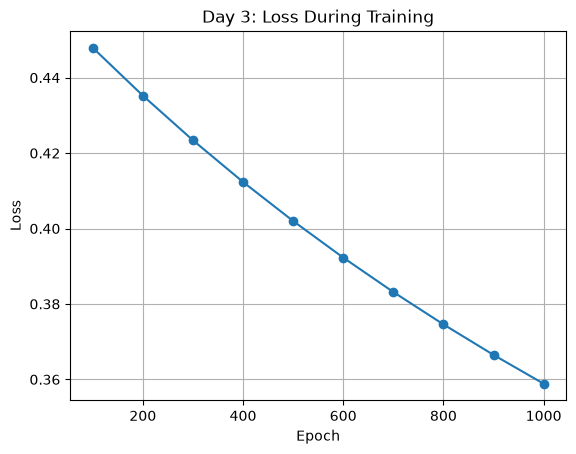

In [39]:
import matplotlib.pyplot as plt

epochs_recorded = range(100, 1001, 100)

plt.plot(epochs_recorded, loss_history, marker="o")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Day 3: Loss During Training")
plt.grid(True)
plt.show()

In [40]:
final_predictions = 1 / (1 + np.exp(-(np.dot(X, weights) + bias)))

predicted_classes = (final_predictions >= 0.5).astype(int)

accuracy = np.mean(predicted_classes == y) * 100

print("Final Probabilities:", final_predictions)
print("Predicted Classes:", predicted_classes)
print("Actual Labels:", y)
print("Accuracy:", accuracy, "%")

Final Probabilities: [0.28381825 0.39522846 0.51869786 0.63992519 0.74559452]
Predicted Classes: [0 0 1 1 1]
Actual Labels: [0 0 0 1 1]
Accuracy: 80.0 %


In [41]:
for i in range(len(y)):
    print(
        "Actual:", y[i],
        "| Predicted:", predicted_classes[i],
        "| Correct:", y[i] == predicted_classes[i]
    )

Actual: 0 | Predicted: 0 | Correct: True
Actual: 0 | Predicted: 0 | Correct: True
Actual: 0 | Predicted: 1 | Correct: False
Actual: 1 | Predicted: 1 | Correct: True
Actual: 1 | Predicted: 1 | Correct: True


In [42]:
print("Third data point probability:", final_predictions[2])
print("Classification threshold:", 0.5)

Third data point probability: 0.518697860433442
Classification threshold: 0.5


In [43]:
new_threshold = 0.55

new_classes = (final_predictions >= new_threshold).astype(int)

new_accuracy = np.mean(new_classes == y) * 100

print("New Threshold:", new_threshold)
print("New Predictions:", new_classes)
print("New Accuracy:", new_accuracy, "%")

New Threshold: 0.55
New Predictions: [0 0 0 1 1]
New Accuracy: 100.0 %


In [44]:
from_threshold = 0.55

final_classes = (final_predictions >= from_threshold).astype(int)

print("Actual Labels:", y)
print("Final Predictions:", final_classes)
print("Correct Predictions:", np.sum(final_classes == y), "out of", len(y))
print("Final Accuracy:", np.mean(final_classes == y) * 100, "%")

Actual Labels: [0 0 0 1 1]
Final Predictions: [0 0 0 1 1]
Correct Predictions: 5 out of 5
Final Accuracy: 100.0 %
